# AI Prediction Scores

Compare the AI prediction scores in ClinVar variants and 1% variants.

In [5]:
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## Loading data

### VarChAMP variants (~8k)

In [6]:
varchamp_al_df = pl.scan_csv("../../1_allele_collection/3_outputs/varchamp_consolidated_alleles_clinvar_gnomad.tsv", 
                            infer_schema_length=10000, 
                            separator="\t")
varchamp_al_df.collect()

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,chrom,ref,alt,varid,gnomad_af
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,f64,str,str,f64,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,str,str,str,str,str,f64
2,"""GBA""","""160G>C""","""Val54Leu""","""ENSG00000177628""","""1""",155240033,"""NC_000001.11:155240033:C:G""","""ALE0000584""","""CCSBVarC000001""","""6""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""F12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""G""","""C""","""1-155240033-G-C""",null
2,"""GBA""","""670C>T""","""Leu224Phe""","""ENSG00000177628""","""1""",155238225,"""NC_000001.11:155238225:G:A""","""ALE00000002""","""CCSBVarC000002""","""73""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""C12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""chr1""","""C""","""T""","""1-155238225-C-T""",null
2,"""GBA""","""887G>A""","""Arg296Gln""","""ENSG00000177628""","""1""",155237453,"""NC_000001.11:155237453:C:T""","""ALE00000003""","""CCSBVarC000003""","""113""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""D12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19367.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.887G>A (p.…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic""",1.0,"""Feb 09, 2024""",7.8973108e7,"""-""","""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55237453e8,1.55237453e8,"""1q22""","""criteria provided, multiple su…",15.0,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3.0,4328.0,1.55237453e8,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2.0,"""1_Pathogenic""","""chr1""","""G""","""A""","""1-155237453-G-A""",null
2,"""GBA""","""1448T>C""","""Leu483Pro""","""ENSG00000177628""","""1""",155235252,"""NC_000001.11:155235252:A:G""","""ALE00000004""","""CCSBVarC000004""","""231""","""NULL""","""NULL""","""GDEhDisVCh_40054""","""E12""","""RC4""","""ATGGAGTTTTCAAGTCCTTCCAGAGAGGAA…",19327.0,"""single nucleotide variant""","""NM_000157.4(GBA1):c.1448T>C (p…",2629.0,"""GBA1""","""HGNC:4177""","""Pathogenic; risk factor""",1.0,"""Nov 27, 2024""",421016.0,"""-""","""RCV000004509|RCV000004511|RCV0…","""MONDO:MONDO:0009266,MedGen:C02…","""Gaucher disease type II|Gauche…","""biparental;de novo;germline;in…","""germline""","""GRCh38""","""NC_000001.11""","""1""",1.55235

### dbNSFP variants (~1.6M)

In [7]:
df_clinvar = pl.scan_parquet("../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")

### Merge them together

In [8]:
varchamp_al_df_ai_scores = varchamp_al_df.join(
    df_clinvar, how="left", 
    left_on="spdi", right_on="SPDI",
    suffix="_dbnsfp"
)
varchamp_al_df_ai_scores = varchamp_al_df_ai_scores.collect()

In [9]:
varchamp_al_df_ai_dedup = varchamp_al_df_ai_scores.unique(subset=["spdi"], keep="first") ##["symbol","aa_change"]
varchamp_al_df_ai_dedup #.head()

orf_id,symbol,nt_change,aa_change,ensembl_gene_id,chr,chr_pos_38,spdi,ccsb_allele_id,ccsb_mutation_id,mutation_id_rc4,mutation_id_cegs2,mutation_id_edgotyping3,entry_plate,entry_well,collection,sequence,#AlleleID,Type,Name,GeneID,GeneSymbol,HGNC_ID,ClinicalSignificance,ClinSigSimple,LastEvaluated,RS# (dbSNP),nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,…,RS# (dbSNP)_dbnsfp,nsv/esv (dbVar)_dbnsfp,RCVaccession_dbnsfp,PhenotypeIDS_dbnsfp,PhenotypeList_dbnsfp,Origin_dbnsfp,OriginSimple_dbnsfp,Assembly_dbnsfp,ChromosomeAccession_dbnsfp,Chromosome_dbnsfp,Start_dbnsfp,Stop_dbnsfp,Cytogenetic_dbnsfp,ReviewStatus_dbnsfp,NumberSubmitters_dbnsfp,Guidelines_dbnsfp,TestedInGTR_dbnsfp,OtherIDs_dbnsfp,SubmitterCategories_dbnsfp,VariationID_dbnsfp,PositionVCF_dbnsfp,ReferenceAlleleVCF_dbnsfp,AlternateAlleleVCF_dbnsfp,SomaticClinicalImpact_dbnsfp,SomaticClinicalImpactLastEvaluated_dbnsfp,ReviewStatusClinicalImpact_dbnsfp,Oncogenicity_dbnsfp,OncogenicityLastEvaluated_dbnsfp,ReviewStatusOncogenicity_dbnsfp,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp
i64,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,str,str,f64,str,str,f64,str,str,str,f64,str,f64,str,str,str,str,str,str,str,str,str,f64,…,i64,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
71569,"""OTC""","""240G>T""","""Lys80Asn""","""ENSG00000036473""","""X""",38369819,"""NC_000023.11:38369819:G:T""","""ALE00005236""","""CCSBVarC005236""","""NULL""","""205820""","""NULL""","""GDEhDisVCh_40048""","""B07""","""CEGS2""","""ATGCTGTTTAATCTGAGGATCCTGTTAAAC…",103032.0,"""single nucleotide variant""","""NM_000531.6(OTC):c.240G>T (p.L…",5009.0,"""OTC""","""HGNC:8512""","""Pathogenic""",1.0,"""-""",7.2554333e7,"""-""","""RCV000083371""","""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",3.8369819e7,…,72554333,"""-""","""RCV000083371""","""MedGen:CN517202""","""not provided""","""unknown""","""unknown""","""GRCh38""","""NC_000023.11""","""X""",38369819,38369819,"""Xp11.4""","""no assertion criteria provided""",1,"""ACMG2016,ACMG2021,ACMG2022""","""N""","""ClinGen:CA224512""",2,97140,38369819,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000115457""","""-""","""-""","""240G>T ""","""Lys80Asn""","""NM_000531.6""",null,"""1_Pathogenic"""
575,"""AGA""","""770C>T""","""Thr257Ile""","""ENSG00000038002""","""4""",177434418,"""NC_000004.12:177434418:G:A""","""ALE00005310""","""CCSBVarC005310""","""NULL""","""213789""","""NULL""","""GDEhDisVCh_40063""","""A09""","""CEGS2""","""ATGGCGCGGAAGTCGAACTTGCCTGTGCTT…",70592.0,"""single nucleotide variant""","""NM_000027.4(AGA):c.770C>T (p.T…",175.0,"""AGA""","""HGNC:318""","""Conflicting classifications of…",1.0,"""Aug 21, 2023""",3.86833434e8,"""-""","""RCV000049362""","""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",1.77434418e8,…,386833434,"""-""","""RCV000049362""","""Human Phenotype Ontology:HP:00…","""Aspartylglucosaminuria""","""germline;unknown""","""germline""","""GRCh38""","""NC_000004.12""","""4""",177434418,177434418,"""4q34.3""","""criteria provided, conflicting…",3,"""-""","""N""","""ClinGen:CA144033,UniProtKB:P20…",2,55953,177434418,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003525620|SCV004217649""","""-""","""-""","""770C>T ""","""Thr257Ile""","""NM_000027.4""",1,"""3_Conflicting"""
3743,"""LAMP2""","""928G>A""","""Val310Ile""","""ENSG00000005893""","""X""",120442599,"""NC_000023.11:120442599:C:T""","""ALE00000542""","""CCSBVarC000542""","""6896""","""NULL""","""NULL""",

In [12]:
varchamp_al_df_ai_dedup.write_csv("../3_outputs/varchamp_consolidated_alleles_clinvar_gnomad_dbnsfp_scores.tsv", separator="\t")

In [7]:
symbol_counts = varchamp_al_df_ai_dedup.group_by("symbol").len().sort(by="len", descending=True)
print(symbol_counts.head())

shape: (5, 2)
┌────────┬─────┐
│ symbol ┆ len │
│ ---    ┆ --- │
│ str    ┆ u32 │
╞════════╪═════╡
│ GALT   ┆ 193 │
│ SMAD4  ┆ 128 │
│ DES    ┆ 121 │
│ AGXT   ┆ 98  │
│ CBS    ┆ 83  │
└────────┴─────┘


## Summary Plots

In [4]:
df_clinvar = df_clinvar.collect()

In [17]:
df_clinvar

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004201236""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004345528""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004275341""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""

In [16]:
df_clinvar["ReviewStatus"].unique().to_list()

[None,
 'criteria provided, multiple submitters, no conflicts',
 'no assertion criteria provided',
 'criteria provided, single submitter',
 'criteria provided, conflicting classifications',
 'reviewed by expert panel',
 'no classification for the single variant',
 'practice guideline',
 'no classifications from unflagged records',
 'no classification provided',
 '-']

In [11]:
df_clinvar["StarStatus"].unique()

StarStatus
i32
null
1
2
3
4


### ClinVAR alleles vs VarChAMP Alleles

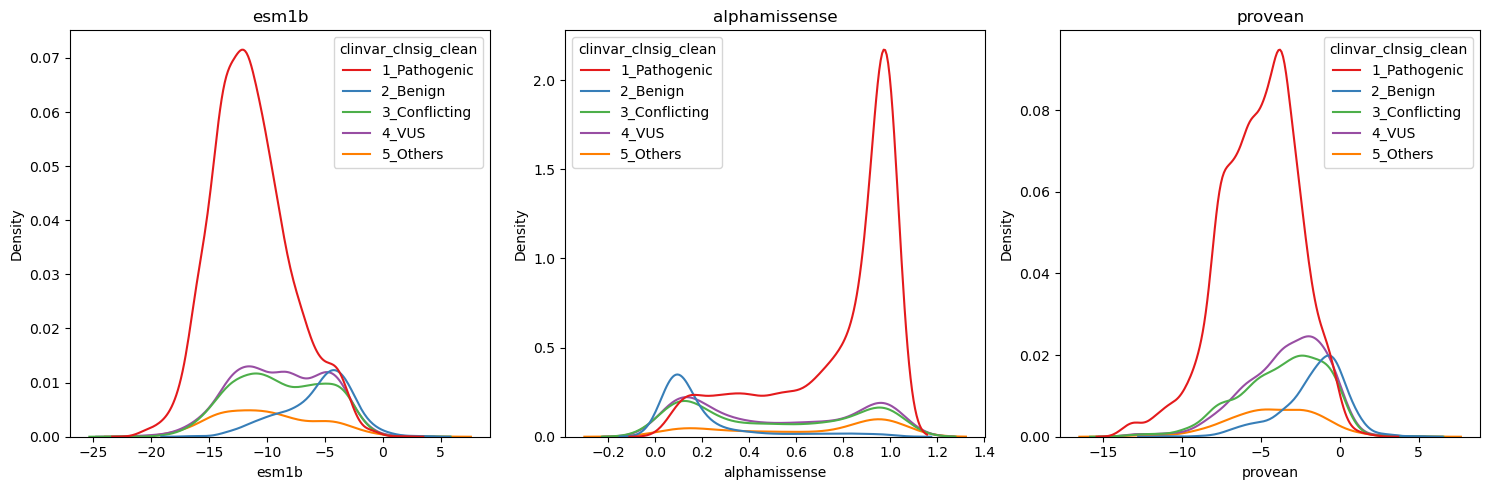

In [ ]:
varchamp_al_df_ai_plots = varchamp_al_df_ai_dedup.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
)

# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) ## , sharey=True
hue_order = sorted(varchamp_al_df_ai_dedup["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=varchamp_al_df_ai_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax,
        palette="Set1"
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

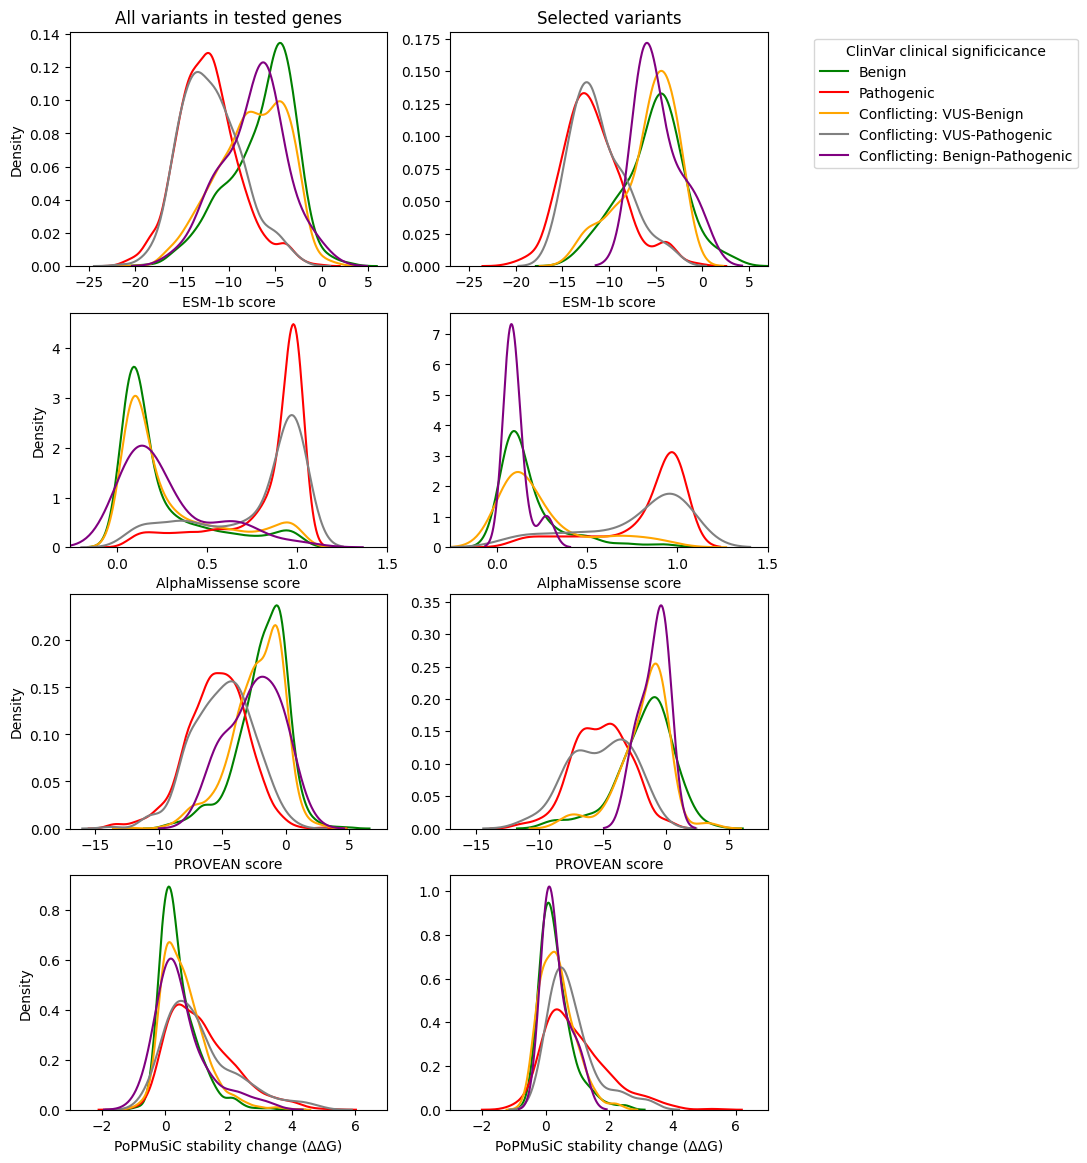

In [ ]:
range_d = {'esm1b':(-27,7),
           'alpha_missense':(-.26,1.5),
           'provean':(-17,8),
           'pop_music':(-3,7),
           'solvant_acc':(0,100),
           'af_plddt':(0,100),
           }

fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(9,14))

for row, assay in zip(axs, ['esm1b','alpha_missense','provean','pop_music']):

    for cs,color in zip(['Benign','Pathogenic'],['green','red']):
        df = clinvar_onepercent[clinvar_onepercent.clinical_significance_simple == cs]
        dfo = clinvar_onepercent[(clinvar_onepercent.clinical_significance_simple == cs)&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=cs)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=cs)
    
    for conflicting_class,color in zip(['Conflicting: Benign-VUS','Conflicting: Pathogenic-VUS','Conflicting: Benign-Pathogenic'],['orange','gray','purple']):
        df = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')]
        dfo = clinvar_onepercent[(clinvar_onepercent.conflicting_class == conflicting_class)&(clinvar_onepercent.clinical_significance_simple == 'Conflicting')&(clinvar_onepercent.one_percent)]
        sns.kdeplot(data=df, x=df[assay], color=color, ax=row[0], label=conflicting_class)
        sns.kdeplot(data=dfo, x=dfo[assay], color=color, ax=row[1], label=conflicting_class)
    
    
    row[0].set_xlim(range_d[assay])
    row[1].set_xlim(range_d[assay])

    if assay == 'esm1b':
        row[1].legend(loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')
        row[0].set_title('All variants in tested genes')
        row[1].set_title('Selected variants')

    axs[0][1].set_ylabel('')
    axs[1][1].set_ylabel('')
    axs[2][1].set_ylabel('')
    axs[3][1].set_ylabel('')

    axs[0][0].set_xlabel('ESM-1b score')
    axs[0][1].set_xlabel('ESM-1b score')
    axs[1][0].set_xlabel('AlphaMissense score')
    axs[1][1].set_xlabel('AlphaMissense score')
    axs[2][0].set_xlabel('PROVEAN score')
    axs[2][1].set_xlabel('PROVEAN score')
    axs[3][0].set_xlabel('PoPMuSiC stability change (ΔΔG)')
    axs[3][1].set_xlabel('PoPMuSiC stability change (ΔΔG)')

# Edit legend labels using dictionary
legend_label_dict = {
    'Conflicting: Benign-VUS':'Conflicting: VUS-Benign',
    'Conflicting: Pathogenic-VUS':'Conflicting: VUS-Pathogenic',
}
handles, labels = row[1].get_legend_handles_labels()
new_labels = [legend_label_dict.get(label, label) for label in labels]
axs[0][1].legend(handles, new_labels, loc='upper right', bbox_to_anchor=(2, 1), title='ClinVar clinical significicance')

plt.show()